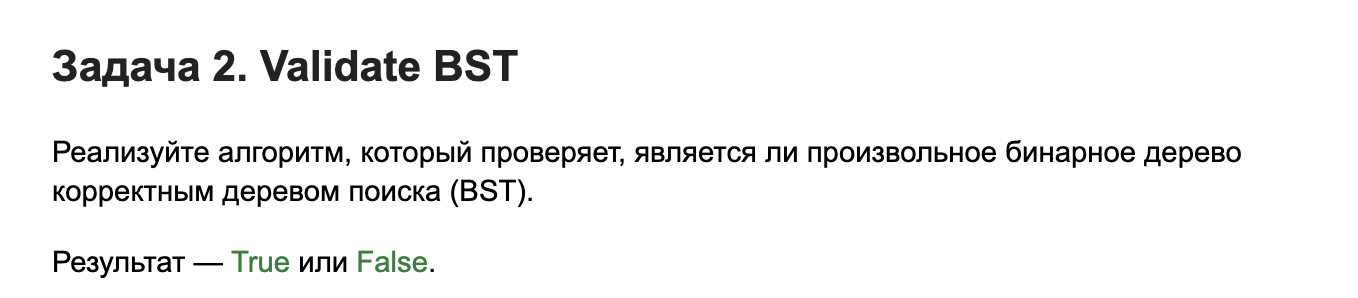

## Ход решения

Просто сравнивать вершину с её непосредственными детьми недостаточно, поскольку значение может быть больше родителя, но нарушать ограничение от более далёкой вершины - предка.

Поэтому используем рекурсивный **DFS** и для каждой вершины передаём допустимый интервал `(low, high)`.

1. Начинаем с корня: его диапазон `(-∞, +∞)`.
2. Если вершина пустая (`None`), возвращаем `True` — проверять больше нечего.
3. Если `node.value` не лежит **строго между** `low` и `high`, возвращаем `False`.
4. При переходе **влево** сохраняем `low` и обновляем `high = node.value`, потому что все значения слева должны быть меньше текущего.
5. При переходе **вправо** обновляем `low = node.value` и сохраняем `high`, потому что все значения справа должны быть больше текущего.
6. Дерево корректно, только если обе рекурсивные проверки вернули `True`.

Этот алгоритм работает, потому что границы учитывают ограничения от всех предков, а не только от непосредственного родителя. Поэтому никакая вершина не может оказаться «не на своей стороне» дерева. Потому что у нас, когда мы идем налево, low сохранется, и меняется high, и наоборот для правых веток. Ну и благодаря этому мы сохраняем локальные минимумы и максимумы для каждой вершины, которые не должны нарушаться.


## Сложность алгоритма

- **Время — `O(n)`**, где `n` — число вершин. В худшем случае DFS посещает каждую вершину один раз.
- **Дополнительная память — `O(h)`**, где `h` — высота дерева: столько вызовов функции одновременно находится в стеке рекурсии.

Для сбалансированного дерева `h = O(log n)`, для вырожденного (цепочки) `h = O(n)`.

## Реализация

Используем поле `value`, как в классе `Node` из предыдущей задачи. Параметры `left` и `right` в конструкторе нужны только для удобного создания деревьев в тестах.

In [7]:
class Node:
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right


def is_valid_bst(root):
    def dfs(node, low, high):
        if node is None:
            return True

        if not low < node.value < high:
            return False

        return (
            dfs(node.left, low, node.value)
            and dfs(node.right, node.value, high)
        )

    return dfs(root, float('-inf'), float('inf'))

## Визуализация работы алгоритма

Рассмотрим дерево из **15 вершин**. У вершины `22` есть правильный непосредственный родитель `15`, но она находится в **левом поддереве корня `20`**, поэтому дерево некорректно.


DFS проверяет левое поддерево перед правым. Для каждой посещённой вершины вычисляются собственные границы:

                 20
              /      \
            10        30
           /  \      /  \
          5    15   25   35
         / \   / \  / \  / \
        2   8 12 22 23 27 32 40
        

| Шаг | Вершина | `low` | `high` | Проверка | Результат |
|---:|---:|---:|---:|---|---|
| 1 | 20 | −∞ | +∞ | `−∞ < 20 < +∞` | `True` |
| 2 | 10 | −∞ | 20 | `−∞ < 10 < 20` | `True` |
| 3 | 5 | −∞ | 10 | `−∞ < 5 < 10` | `True` |
| 4 | 2 | −∞ | 5 | `−∞ < 2 < 5` | `True` |
| 5 | 8 | 5 | 10 | `5 < 8 < 10` | `True` |
| 6 | 15 | 10 | 20 | `10 < 15 < 20` | `True` |
| 7 | 12 | 10 | 15 | `10 < 12 < 15` | `True` |
| **8** | **22** | **15** | **20** | **`15 < 22 < 20`** | **`False`** |

Переход `20 → 10 → 15 → 22` особенно важен:

- Слева от `20` сохраняется `high = 20`.
- При переходе вправо от `10` устанавливаем `low = 10`, но оставляем `high = 20`.
- При переходе вправо от `15` устанавливаем `low = 15`, а `high = 20` всё ещё сохраняется.
- Вершина `22` нарушает условие `15 < 22 < 20`, поэтому результат всего дерева — `False`.

Пустые дети (`None`) в таблице опущены. После первого `False` дальнейшие ветви не проверяются из-за оператора `and`.

In [8]:
invalid_tree = Node(
    20,
    Node(10, Node(5, Node(2), Node(8)), Node(15, Node(12), Node(22))),
    Node(30, Node(25, Node(23), Node(27)), Node(35, Node(32), Node(40))),
)

print(is_valid_bst(invalid_tree))

False


## Тесты

Проверим пустое дерево, одну вершину, обычные BST, нарушения у детей и на глубине, отрицательные и большие числа, повторяющиеся значения и вырожденные деревья.

In [9]:
valid_tree = Node(
    20,
    Node(10, Node(5, Node(2), Node(8)), Node(15, Node(12), Node(17))),
    Node(30, Node(25, Node(23), Node(27)), Node(35, Node(32), Node(40))),
)

tests = [
    ('Пустое дерево', None, True),
    ('Одна вершина', Node(10), True),
    ('Корректное маленькое BST', Node(10, Node(5), Node(15)), True),
    ('Нарушение у левого ребёнка', Node(10, Node(12)), False),
    ('Нарушение у правого ребёнка', Node(10, None, Node(8)), False),
    ('Нарушение ограничения от предка', Node(10, Node(5), Node(15, Node(6), Node(20))), False),
    ('Большое корректное BST', valid_tree, True),
    ('Большое BST с ошибкой', invalid_tree, False),
    ('Дубликат слева', Node(10, Node(10)), False),
    ('Дубликат справа', Node(10, None, Node(10)), False),
    ('Дубликат на глубине', Node(10, Node(5), Node(15, Node(10), Node(20))), False),
    ('Цепочка влево', Node(5, Node(4, Node(3, Node(2)))), True),
    ('Цепочка вправо', Node(5, None, Node(6, None, Node(7))), True),
    ('Отрицательные числа', Node(-10, Node(-20), Node(-5)), True),
    ('Нарушение с отрицательными числами', Node(-10, Node(-20, None, Node(-1)), Node(2)), False),
    ('Большие значения', Node(10**30, Node(-10**30), Node(10**40)), True),
]

for name, tree, expected in tests:
    actual = is_valid_bst(tree)
    assert actual == expected, f'{name}: ожидалось {expected}, получено {actual}'

print(f'Все {len(tests)} тестов пройдены.')

Все 16 тестов пройдены.
